In [1]:
!pip install -U keras tensorflow "huggingface_hub<2.0" pillow matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 40.5 MB/s eta 0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface_hub 2.1.1
    Uninstalling huggingface_hub-2.1.1:
      Successfully uninstalled huggingface_hub-2.1.1


In [4]:
import os

# Use TensorFlow backend
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
import numpy as np
import matplotlib.pyplot as plt
from huggingface_hub import HfApi, hf_hub_download

repo_id = "Adi2912/DenseNet169_PlantVillagePotatoLeaf"

try:
    # List all files in the Hugging Face repository to identify the correct filename
    api = HfApi()
    files = api.list_repo_files(repo_id=repo_id)
    print("Files available in the repository:")
    for f in files:
        print(f"- {f}")

    # Find the model file (typically ending in .keras, .h5, or model structure)
    model_file = next((f for f in files if f.endswith(".keras") or f.endswith(".h5")), None)

    if model_file:
        print(f"\nDownloading identified model file: {model_file}...")
        model_path = hf_hub_download(repo_id=repo_id, filename=model_file)
        model = keras.saving.load_model(model_path)
        print("Model loaded successfully!")
        print("Input shape:", model.input_shape)
    else:
        print("\nNo standard model file (.keras or .h5) found in the repository root.")
except Exception as e:
    print(f"An error occurred during listing/loading: {e}")

Files available in the repository:
- .gitattributes
- README.md
- best.keras

Model loaded successfully!
Input shape: (None, 224, 224, 3)


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1018 variables whereas the saved optimizer has 1022 variables. 
  saveable.load_own_variables(store)


Saving potato healthy.jpg to potato healthy.jpg


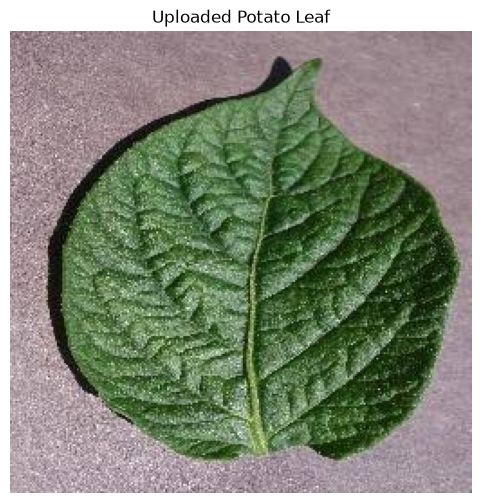

       POTATO LEAF DISEASE PREDICTION
Predicted Disease : Late Blight
Confidence        : 100.00%

Class Probabilities:
Early Blight   : 0.00%
Late Blight    : 100.00%
Healthy        : 0.00%


In [6]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Upload image
uploaded = files.upload()

# Get uploaded file name
image_path = list(uploaded.keys())[0]

# Open image
image = Image.open(image_path).convert("RGB")

# Display original image
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Potato Leaf")
plt.show()

# Resize image to model input size
image_resized = image.resize((224, 224))

# Convert image to numpy array
image_array = np.array(image_resized)

# Normalize pixel values
image_array = image_array / 255.0

# Add batch dimension
image_array = np.expand_dims(image_array, axis=0)

# Make prediction
predictions = model.predict(image_array, verbose=0)

# Class names according to the model
class_names = [
    "Early Blight",
    "Late Blight",
    "Healthy"
]

# Get predicted class
predicted_index = np.argmax(predictions[0])
predicted_class = class_names[predicted_index]

# Get confidence
confidence = predictions[0][predicted_index] * 100

# Display result
print("=" * 50)
print("       POTATO LEAF DISEASE PREDICTION")
print("=" * 50)

print(f"Predicted Disease : {predicted_class}")
print(f"Confidence        : {confidence:.2f}%")

print("=" * 50)

# Display probabilities for all classes
print("\nClass Probabilities:")

for class_name, probability in zip(class_names, predictions[0]):
    print(f"{class_name:15s}: {probability * 100:.2f}%")